# Life Expectancy Analysis (WHO Data)
**Students:** Janmejaynarayan Rawal (IU2441230577), Harsh Sorathiya (IU2441230562)
**Course:** Python Programming | **Guide:** Prof. Vatsal Shinghala
**GitHub:** https://github.com/JayJOD10/life-expectancy-analysis

This notebook cleans the WHO Life Expectancy dataset, runs statistical tests and draws 10 graphs. Run the cells from top to bottom (Runtime > Run all).

## 1. Import libraries

In [1]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

## 2. Load the dataset
The file is read from our GitHub repository. If that fails, Colab will ask you to upload `Life Expectancy Data.csv` yourself.

In [2]:
url = "https://raw.githubusercontent.com/JayJOD10/life-expectancy-analysis/main/Life%20Expectancy%20Data.csv"
try:
    df = pd.read_csv(url)
except Exception:
    from google.colab import files
    uploaded = files.upload()
    df = pd.read_csv(list(uploaded.keys())[0])

print("Rows and columns:", df.shape)
df.head()

Rows and columns: (2938, 22)


,Country,Year,Status,Life_expectancy,Adult_Mortality,Infant_deaths,Alcohol,Percentage_expenditure,Hepatitis_B,Measles,...,Polio,Total_expenditure,Diphtheria,HIV_AIDS,GDP,Population,Thinness_1_19_years,Thinness_5_9_years,Income_composition_of_resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,NaN,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


## 3. Clean the column names
Some column names have extra spaces or symbols (for example `Adult Mortality ` or ` HIV/AIDS`). A regular expression turns them into clean names.

In [3]:
GOOD = ["Country","Year","Status","Life_expectancy","Adult_Mortality","Infant_deaths","Alcohol",
        "Percentage_expenditure","Hepatitis_B","Measles","BMI","Under_five_deaths","Polio",
        "Total_expenditure","Diphtheria","HIV_AIDS","GDP","Population","Thinness_1_19_years",
        "Thinness_5_9_years","Income_composition_of_resources","Schooling"]
lookup = {g.lower(): g for g in GOOD}
df.columns = [lookup.get(re.sub(r"[^0-9a-zA-Z]+", "_", c).strip("_").lower(), c) for c in df.columns]
LE = "Life_expectancy"
print(list(df.columns))

['Country', 'Year', 'Status', 'Life_expectancy', 'Adult_Mortality', 'Infant_deaths', 'Alcohol', 'Percentage_expenditure', 'Hepatitis_B', 'Measles', 'BMI', 'Under_five_deaths', 'Polio', 'Total_expenditure', 'Diphtheria', 'HIV_AIDS', 'GDP', 'Population', 'Thinness_1_19_years', 'Thinness_5_9_years', 'Income_composition_of_resources', 'Schooling']


## 4. Dataset overview

In [4]:
print("Countries:", df["Country"].nunique(), "| Years:", df["Year"].min(), "to", df["Year"].max())
print(df.groupby("Status")["Country"].nunique())
df.describe().T.round(2)

Countries: 193 | Years: 2000 to 2015
Status
Developed      34
Developing    159
Name: Country, dtype: int64


,count,mean,std,min,25%,50%,75%,max
Year,2938.0,2007.52,4.61,2000.00,2004.00,2008.00,2012.00,2.015000e+03
Life_expectancy,2928.0,69.22,9.52,36.30,63.10,72.10,75.70,8.900000e+01
Adult_Mortality,2927.0,164.76,124.30,1.00,74.00,144.00,227.50,7.230000e+02
Infant_deaths,2938.0,30.30,117.93,0.00,0.00,3.00,22.00,1.800000e+03
Alcohol,2744.0,4.60,4.05,0.01,0.88,3.76,7.70,1.787000e+01
Percentage_expenditure,2938.0,738.25,1987.91,0.00,4.69,64.91,441.53,1.947991e+04
Hepatitis_B,2385.0,80.94,25.07,1.00,77.00,92.00,97.00,9.900000e+01
Measles,2938.0,2419.59,11467.27,0.00,0.00,17.00,360.25,2.121830e+05
BMI,2904.0,38.32,20.04,1.00,19.30,43.50,56.20,8.730000e+01
Under_five_deaths,2938.0,42.04,160.45,0.00,0.00,4.00,28.00,2.500000e+03


## 5. Missing values

Population                         652
Hepatitis_B                        553
GDP                                448
Total_expenditure                  226
Alcohol                            194
Income_composition_of_resources    167
Schooling                          163
Thinness_1_19_years                 34
Thinness_5_9_years                  34
BMI                                 34
Diphtheria                          19
Polio                               19
Adult_Mortality                     11
Life_expectancy                     10
dtype: int64


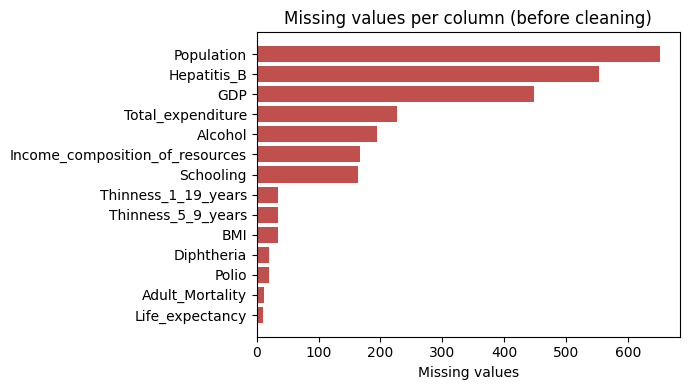

In [5]:
miss = df.isna().sum().sort_values(ascending=False)
miss = miss[miss > 0]
print(miss)

plt.figure(figsize=(7,4))
plt.barh(miss.index[::-1], miss.values[::-1], color="#c0504d")
plt.xlabel("Missing values"); plt.title("Missing values per column (before cleaning)")
plt.tight_layout(); plt.show()

## 6. Fill the missing values
Each gap is filled with the median of the same country. Anything still empty gets the overall median.

In [6]:
num = df.select_dtypes("number").columns.drop("Year")
df[num] = df.groupby("Country")[num].transform(lambda s: s.fillna(s.median()))
df[num] = df[num].fillna(df[num].median())
print("Missing values left:", df.isna().sum().sum())

Missing values left: 0


## 7. Distribution of life expectancy

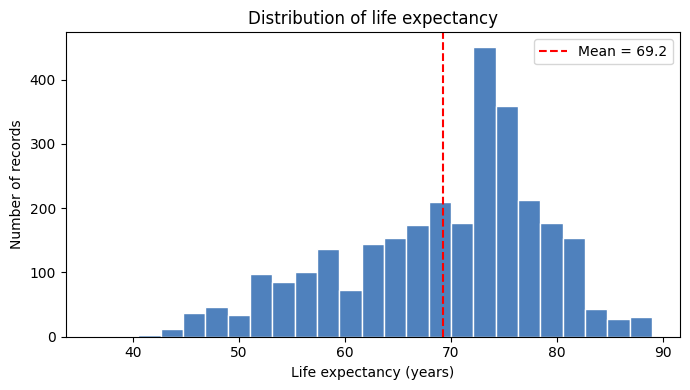

Mean: 69.2 | Median: 72.1 | Std: 9.5 | Min: 36.3 | Max: 89.0


In [7]:
plt.figure(figsize=(7,4))
plt.hist(df[LE], bins=25, color="#4f81bd", edgecolor="white")
plt.axvline(df[LE].mean(), color="red", ls="--", label=f"Mean = {df[LE].mean():.1f}")
plt.xlabel("Life expectancy (years)"); plt.ylabel("Number of records")
plt.title("Distribution of life expectancy"); plt.legend(); plt.tight_layout(); plt.show()

print("Mean:", round(df[LE].mean(),1), "| Median:", df[LE].median(), "| Std:", round(df[LE].std(),1),
      "| Min:", df[LE].min(), "| Max:", df[LE].max())

## 8. Developed vs developing countries (box plot and t-test)

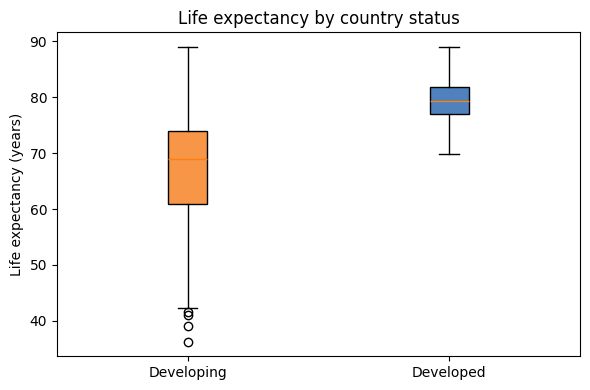

Developed mean: 79.4 | Developing mean: 66.9
Welch t-test: t = 50.2, p = 0  -> the difference is significant


In [8]:
dev = df[df.Status=="Developed"][LE]
dvg = df[df.Status=="Developing"][LE]

plt.figure(figsize=(6,4))
bp = plt.boxplot([dvg, dev], patch_artist=True)
plt.xticks([1,2], ["Developing","Developed"])
for p,c in zip(bp["boxes"],["#f79646","#4f81bd"]): p.set_facecolor(c)
plt.ylabel("Life expectancy (years)"); plt.title("Life expectancy by country status")
plt.tight_layout(); plt.show()

t, p = stats.ttest_ind(dev, dvg, equal_var=False)
print(f"Developed mean: {dev.mean():.1f} | Developing mean: {dvg.mean():.1f}")
print(f"Welch t-test: t = {t:.1f}, p = {p:.3g}  -> the difference is significant")

## 9. Trend from 2000 to 2015

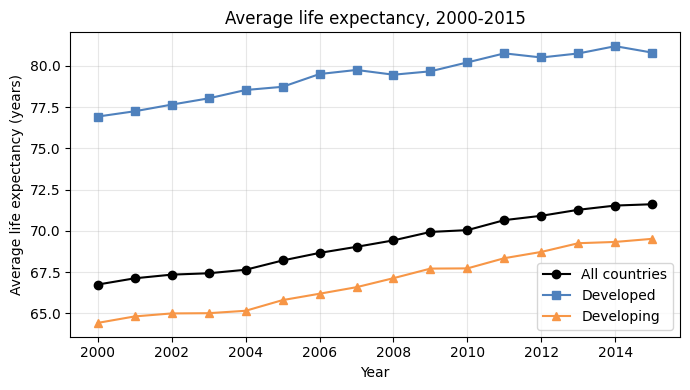

All countries: 66.8 -> 71.6
Developing gain: 5.1 years
Developed gain: 3.9 years
Gap in 2000: 12.5 | Gap in 2015: 11.3


In [9]:
trend = df.groupby(["Year","Status"])[LE].mean().unstack()
allyr = df.groupby("Year")[LE].mean()

plt.figure(figsize=(7,4))
plt.plot(allyr.index, allyr.values, "k-o", label="All countries")
plt.plot(trend.index, trend["Developed"], "-s", color="#4f81bd", label="Developed")
plt.plot(trend.index, trend["Developing"], "-^", color="#f79646", label="Developing")
plt.xlabel("Year"); plt.ylabel("Average life expectancy (years)")
plt.title("Average life expectancy, 2000-2015"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("All countries:", round(allyr.iloc[0],1), "->", round(allyr.iloc[-1],1))
print("Developing gain:", round(trend['Developing'].iloc[-1]-trend['Developing'].iloc[0],1), "years")
print("Developed gain:", round(trend['Developed'].iloc[-1]-trend['Developed'].iloc[0],1), "years")
print("Gap in 2000:", round(trend['Developed'].iloc[0]-trend['Developing'].iloc[0],1),
      "| Gap in 2015:", round(trend['Developed'].iloc[-1]-trend['Developing'].iloc[-1],1))

## 10. Correlation heatmap

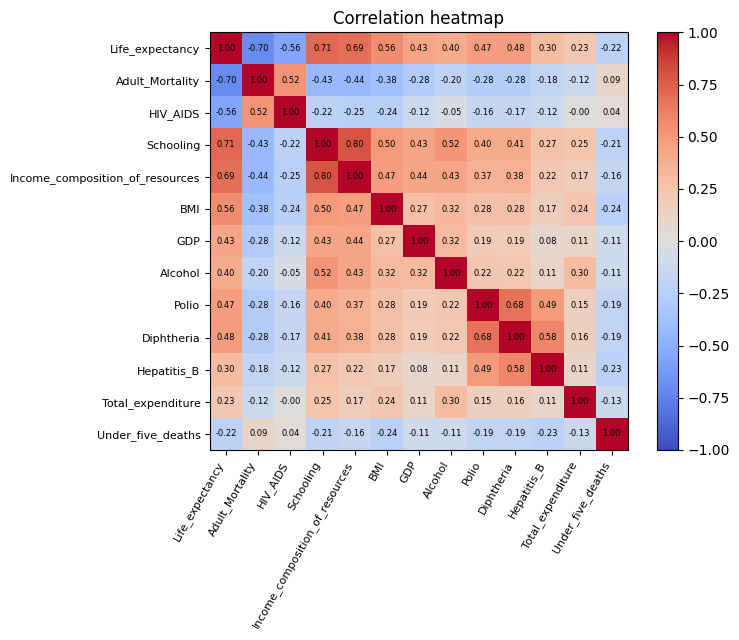

Adult_Mortality                   -0.696405
HIV_AIDS                          -0.556703
Under_five_deaths                 -0.222738
Total_expenditure                  0.226429
Hepatitis_B                        0.300867
Alcohol                            0.404035
GDP                                0.431460
Polio                              0.470517
Diphtheria                         0.484029
BMI                                0.556901
Income_composition_of_resources    0.688662
Schooling                          0.713054
Life_expectancy                    1.000000
Name: Life_expectancy, dtype: float64


In [10]:
cols = [LE,"Adult_Mortality","HIV_AIDS","Schooling","Income_composition_of_resources","BMI","GDP",
        "Alcohol","Polio","Diphtheria","Hepatitis_B","Total_expenditure","Under_five_deaths"]
cm = df[cols].corr()

plt.figure(figsize=(8,6.5))
plt.imshow(cm, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(cols)), cols, rotation=60, ha="right", fontsize=8)
plt.yticks(range(len(cols)), cols, fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        plt.text(j, i, f"{cm.iloc[i,j]:.2f}", ha="center", va="center", fontsize=6)
plt.colorbar(fraction=.046); plt.title("Correlation heatmap"); plt.tight_layout(); plt.show()

print(cm[LE].sort_values())

## 11. Regression: schooling, adult mortality and GDP vs life expectancy

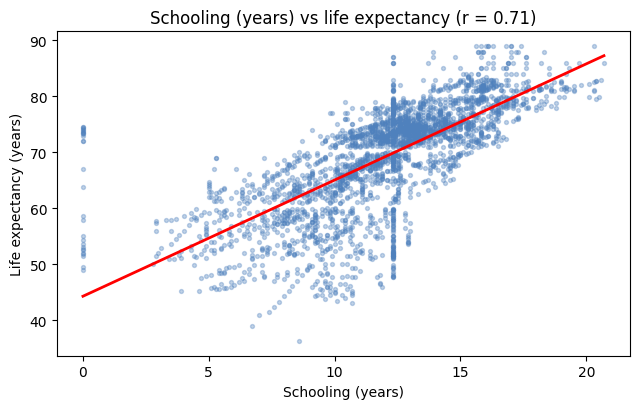

Schooling: slope = 2.077, r = 0.71, R2 = 0.51



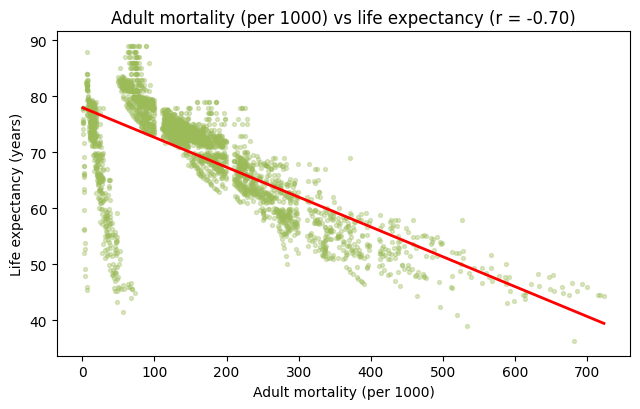

Adult_Mortality: slope = -0.053, r = -0.70, R2 = 0.48



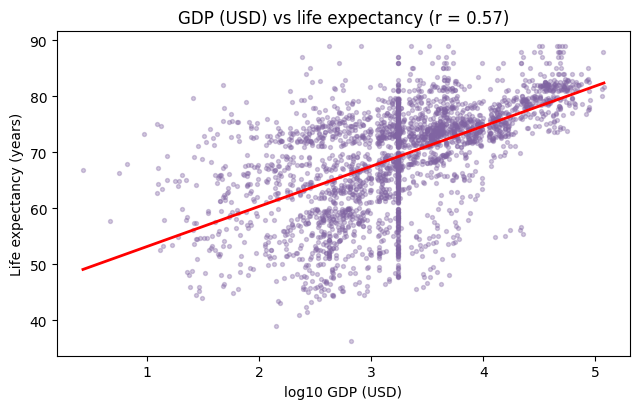

GDP: slope = 7.170, r = 0.57, R2 = 0.32



In [11]:
def scatter(x, label, color, log=False):
    d = df[[x, LE]].dropna()
    xv = np.log10(d[x] + 1) if log else d[x]
    r = stats.linregress(xv, d[LE])
    plt.figure(figsize=(6.5,4.2))
    plt.scatter(xv, d[LE], s=8, alpha=.35, color=color)
    xs = np.linspace(xv.min(), xv.max(), 50)
    plt.plot(xs, r.intercept + r.slope*xs, "r-", lw=2)
    plt.xlabel(("log10 " if log else "") + label); plt.ylabel("Life expectancy (years)")
    plt.title(f"{label} vs life expectancy (r = {r.rvalue:.2f})")
    plt.tight_layout(); plt.show()
    print(f"{x}: slope = {r.slope:.3f}, r = {r.rvalue:.2f}, R2 = {r.rvalue**2:.2f}\n")

scatter("Schooling", "Schooling (years)", "#4f81bd")
scatter("Adult_Mortality", "Adult mortality (per 1000)", "#9bbb59")
scatter("GDP", "GDP (USD)", "#8064a2", log=True)

## 12. Highest and lowest countries

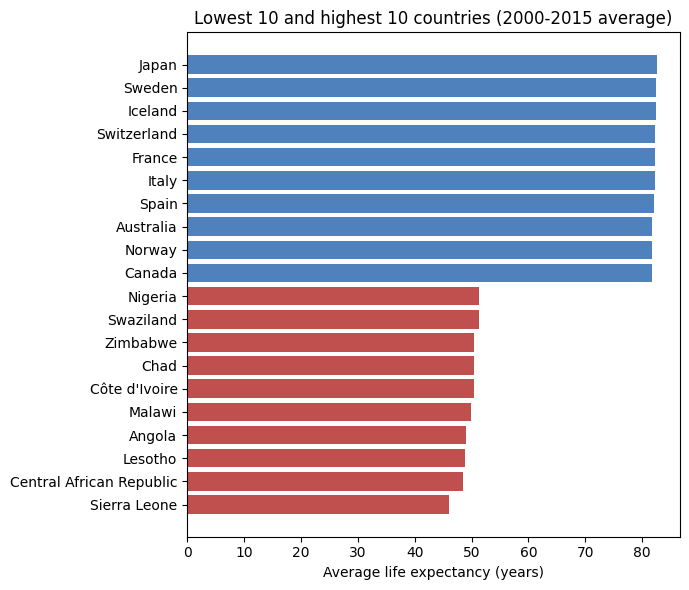

In [12]:
cavg = df.groupby("Country")[LE].mean().sort_values()
sel = pd.concat([cavg.head(10), cavg.tail(10)])

plt.figure(figsize=(7,6))
plt.barh(sel.index, sel.values, color=["#c0504d"]*10 + ["#4f81bd"]*10)
plt.xlabel("Average life expectancy (years)")
plt.title("Lowest 10 and highest 10 countries (2000-2015 average)")
plt.tight_layout(); plt.show()

## 13. Immunization coverage

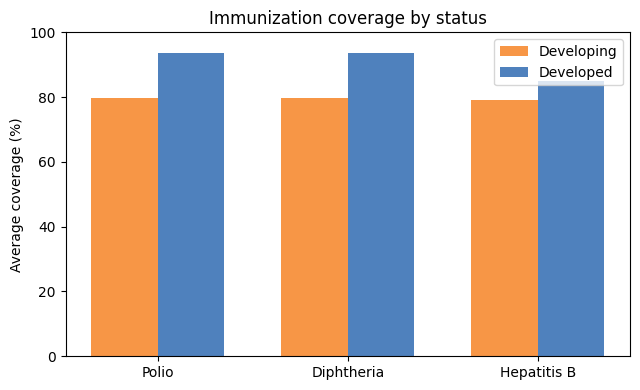

,Polio,Diphtheria,Hepatitis_B
Status,,,
Developed,93.6,93.5,84.9
Developing,79.9,79.6,79.0


In [13]:
imm = df.groupby("Status")[["Polio","Diphtheria","Hepatitis_B"]].mean()
x = np.arange(3); w = .35

plt.figure(figsize=(6.5,4))
plt.bar(x - w/2, imm.loc["Developing"], w, label="Developing", color="#f79646")
plt.bar(x + w/2, imm.loc["Developed"], w, label="Developed", color="#4f81bd")
plt.xticks(x, ["Polio","Diphtheria","Hepatitis B"])
plt.ylabel("Average coverage (%)"); plt.ylim(0,100); plt.legend()
plt.title("Immunization coverage by status"); plt.tight_layout(); plt.show()
imm.round(1)

## 14. Conclusion
- Developed countries live about 12 years longer on average (79.4 vs 66.9 years).
- Life expectancy rose in all groups from 2000 to 2015, and the gap between developed and developing countries became smaller.
- Schooling and adult mortality are the factors most strongly linked to life expectancy.
- Correlation does not prove cause, and filling missing values with medians can slightly change the numbers.